In [1]:
# Cell 1: Imports and reproducibility
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Cell 2: Load dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)
df = df.dropna().copy()

print("Dataset shape:", df.shape)
display(df.head())
print("\\nClass counts:")
display(df["species"].value_counts())

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


\nClass counts:


,count
species,
setosa,50
versicolor,50
virginica,50


In [3]:
# Cell 3: Basic inspection
display(df.describe(include="all"))
print("Missing values per column:")
display(df.isna().sum())

,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


Missing values per column:


,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


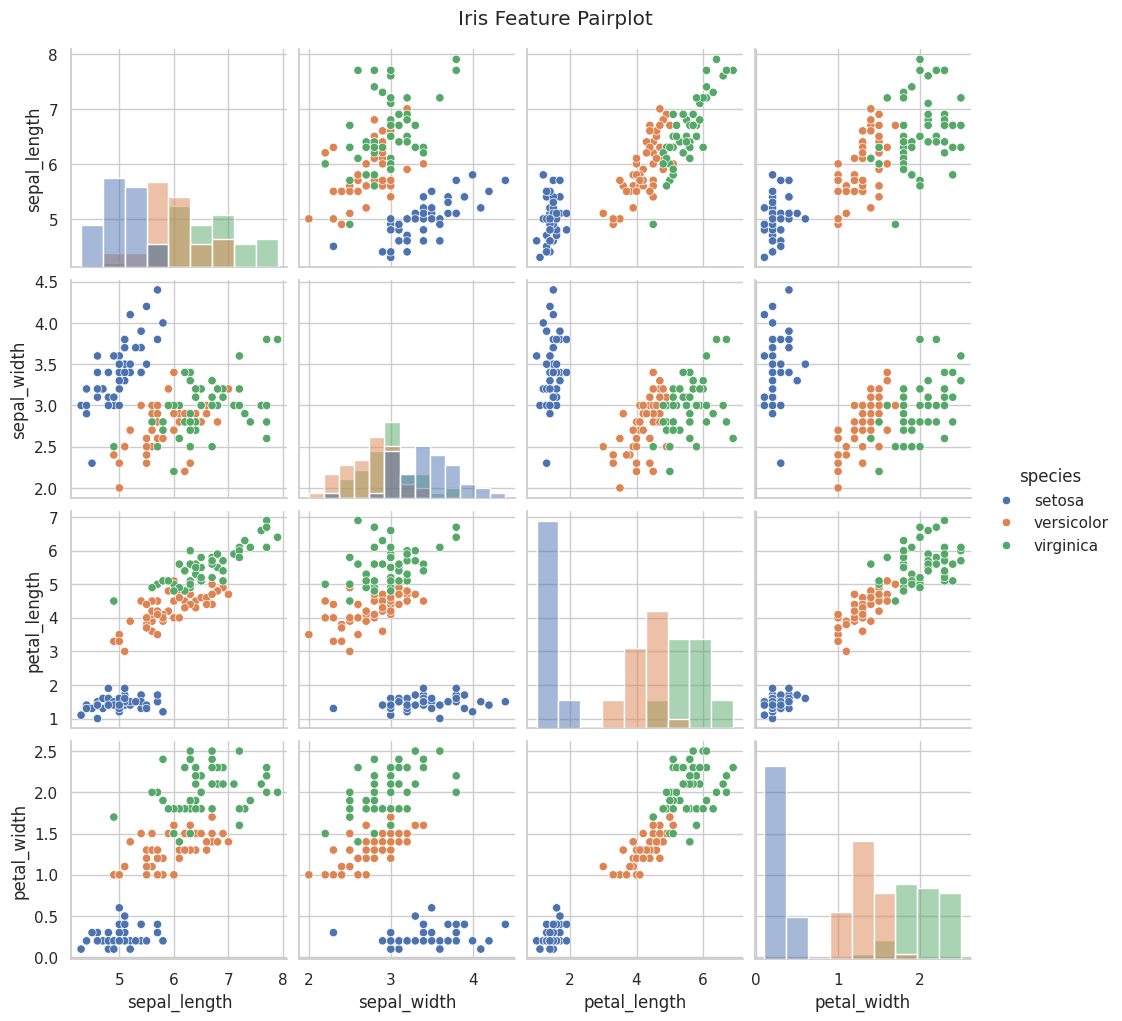

In [4]:
# Cell 4: Exploratory pairplot
sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Feature Pairplot", y=1.02)
plt.show()

In [5]:
# Cell 5: Split features and target (80/20)
X = df.drop(columns="species")
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 120 | Test rows: 30


In [6]:
# Cell 6: Train models using a pipeline
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=4))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


In [7]:
# Cell 7: Evaluate metrics and display classification reports
rows = []
predictions = {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
    })
    print("\\n" + "="*60)
    print(name)
    print(classification_report(y_test, pred, zero_division=0))

metrics_df = pd.DataFrame(rows).sort_values("F1 (macro)", ascending=False)
display(metrics_df.round(4))
metrics_df.to_csv("outputs/task1_classification_metrics.csv", index=False)

\n============================================================
Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

\n============================================================
Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


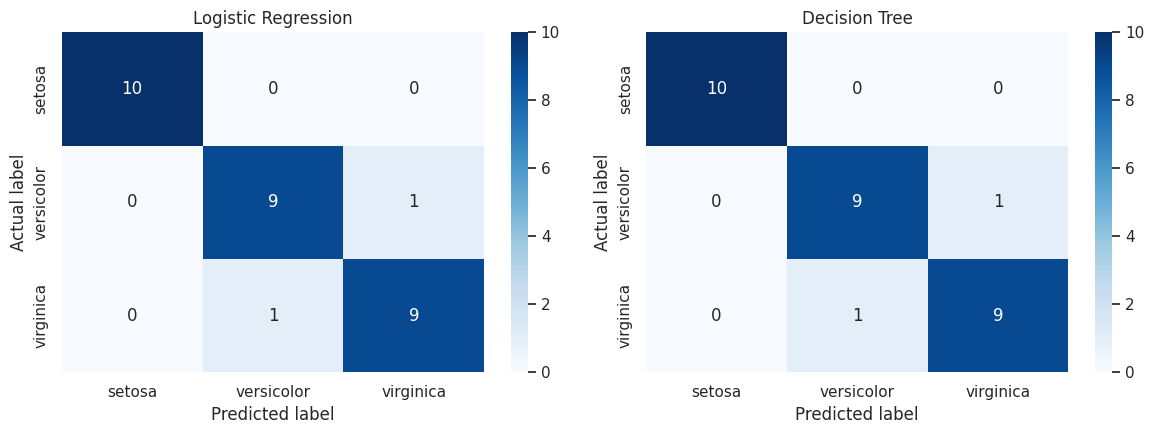

In [8]:
# Cell 8: Confusion matrix heatmaps
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
class_names = sorted(y.unique())

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.savefig("outputs/task1_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

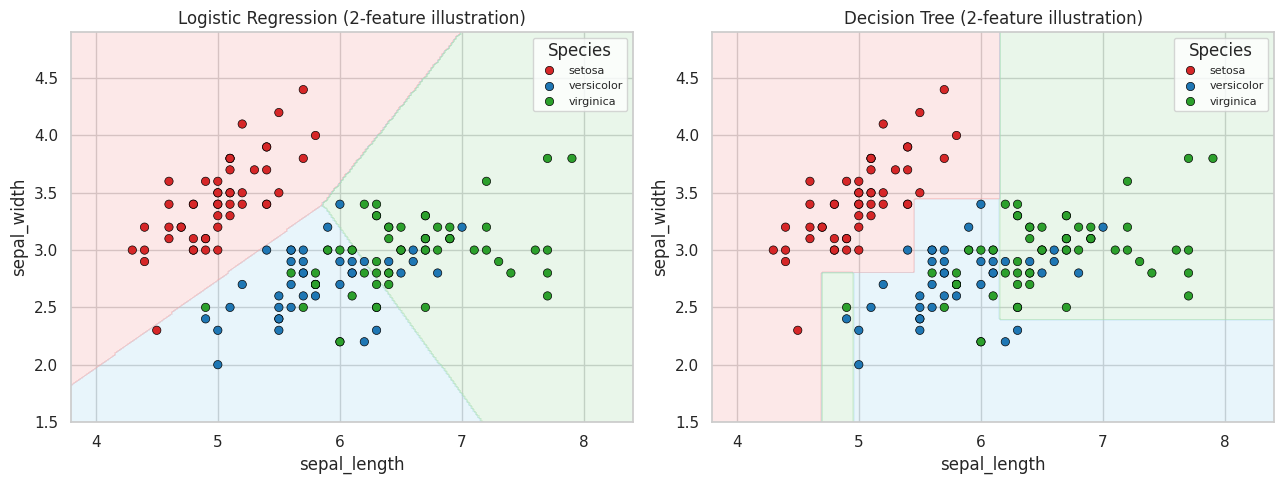

In [9]:
# Cell 9: Decision-boundary visualization using the first two features
# This is a separate 2-feature model for visualization; full-feature models above
# are the ones used for the main benchmark.
from matplotlib.colors import ListedColormap

feature_pair = list(X.columns[:2])
X2 = X[feature_pair]
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cmap = ListedColormap(["#f4a6a6", "#a6d8f0", "#a8dfad"])
for ax, (name, estimator) in zip(axes, [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("Decision Tree", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE))
]):
    viz_model = Pipeline([("scaler", StandardScaler()), ("model", estimator)])
    viz_model.fit(X2_train, y2_train)
    x_min, x_max = X2.iloc[:,0].min()-0.5, X2.iloc[:,0].max()+0.5
    y_min, y_max = X2.iloc[:,1].min()-0.5, X2.iloc[:,1].max()+0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_pair)
    pred_grid = pd.Categorical(viz_model.predict(grid), categories=class_names).codes.reshape(xx.shape)
    ax.contourf(xx, yy, pred_grid, alpha=0.25, cmap=cmap)
    sns.scatterplot(data=df, x=feature_pair[0], y=feature_pair[1], hue="species",
                    palette=["#d62728", "#1f77b4", "#2ca02c"], edgecolor="black", ax=ax)
    ax.set_title(f"{name} (2-feature illustration)")
    ax.legend(title="Species", fontsize=8)
plt.tight_layout()
plt.savefig("outputs/task1_decision_boundaries.png", dpi=160, bbox_inches="tight")
plt.show()